In [59]:
import os
import sys 
print("Active Environment Path:", sys.executable)
from pathlib import Path
import json
import subprocess
import importlib
import tempfile

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, PrecisionRecallDisplay
import shapely

import pystac_client
import planetary_computer
import odc.stac
import rasterio.features

# local
os.chdir("/home/azureuser/EBRD_Tillage/AK_Experiments/AK_pipeline")
sys.path.append(os.getcwd())
from Generic.addSentinelIndices import calculateSentinelIndex, SENTINEL_INDEX_DEPENDENCIES
from utils.classify_tillage import classify_tillage
from ml.nominal_classification import RFC 
from ml.ordinal_regression import RFR

Active Environment Path: /anaconda/envs/geospatial-base/bin/python


In [12]:
# ==============================================================================
# 1. HELPER FUNCTIONS FOR IN-MEMORY STAC & RASTER REDUCTION
# ==============================================================================
def check_xarray_nan(obj):
    if isinstance(obj, xr.Dataset):
        return False
    elif pd.isna(obj):  # Handles float('nan'), np.nan, and None safely
        return True
    else:
        raise 

    
# This needn't be called for every fields, I am calling it for a sample field. 
def get_utm_crs(gdf: gpd.GeoDataFrame) -> str:
    """Determine the local UTM EPSG code from a GeoDataFrame centroid."""
    centroid = gdf.to_crs("EPSG:4326").union_all().centroid
    lon, lat = centroid.x, centroid.y
    zone = int((lon + 180) // 6) + 1
    epsg = 32600 + zone if lat >= 0 else 32700 + zone
    return f"EPSG:{epsg}"

#########################################################33    
def get_sentinel1_STAC(
        geom: shapely.geometry,
        catalog_client: pystac_client.Client,
        utm_crs: str, 
        input_bands :list, 
        start : str,
        end: str, 
        resolution: float = 10.0,
        orbit_direction: str = None,  # Optional: "ascending" or "descending"
):
    """Stream optical bands for a single event directly into memory and return
                Object stored as Xarray Dataset. 
                Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
        """
    # 2. Prepare STAC query filters (No cloud cover filter for SAR)
    query_params = {}

    if orbit_direction in ["ascending", "descending"]:
        query_params["sat:orbit_state"] = {"eq": orbit_direction}

    # 3. STAC Search directly in memory
    search = catalog_client.search(
        collections=["sentinel-1-rtc"],
        intersects=geom.__geo_interface__,
        datetime=f"{start}/{end}",
        query=query_params if query_params else None,
        limit=100,
    )
    items = list(search.items())

    if not items:
        return np.nan

    # Sign asset URLs for Planetary Computer Azure SAS authentication
    items = [planetary_computer.sign(item) for item in items]

    # 4. Project polygon to local UTM for accurate 10m spatial rasterization
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326") 
    event_utm = event_gdf.to_crs(utm_crs)
    minx, miny, maxx, maxy = event_utm.total_bounds
    
     
    # 5. Load Sentinel-1 backscatter assets into memory using odc.stac
    xarray_ds = odc.stac.load(
        items,
        bands=input_bands,  # Usually ['vv', 'vh']
        crs=utm_crs,
        resolution=resolution,
        x=(minx - 20, maxx + 20),
        y=(miny - 20, maxy + 20),
        chunks={},
    ).load()  # Materialize arrays into RAM

    if xarray_ds.sizes.get("time", 0) == 0:
        return np.nan
    #print("Min ",np.array(xarray_ds['vv']).min()," Mean  ",np.array(xarray_ds['vv']).mean())
    # Convert linear amplitude values to float32
    for rawband in list(xarray_ds.data_vars): 
            xarray_ds[rawband] = xarray_ds[rawband].astype("float32")
            xarray_ds[rawband] = xarray_ds[rawband].where(xarray_ds[rawband] > -50.0)

    return xarray_ds
######################################################################################################
def get_sentinel2_STAC(
        geom: shapely.geometry,
        catalog_client: pystac_client.Client, 
        utm_crs: str, 
        input_bands :list, 
        start : str,
        end: str, 
        max_cloud_cover: int = 90,
        resolution: float = 10.0,
    ):
    """Stream optical bands for a single event directly into memory and return
            Object stored as Xarray Dataset. 
            Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
    """

    # 2. STAC Search directly in memory
    search = catalog_client.search(
        collections=["sentinel-2-l2a"],
        intersects=geom.__geo_interface__,
        datetime=f"{start}/{end}",
        query={"eo:cloud_cover": {"lte": max_cloud_cover}},
        limit=100
        )
    items = list(search.items())
    if not items:
            return np.nan
    # Sign asset URLs for Planetary Computer Azure SAS authentication
    items = [planetary_computer.sign(item) for item in items]

    # 3. Project polygon to local UTM for accurate 10m spatial rasterization
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326")
    event_utm = event_gdf.to_crs(utm_crs)
    minx, miny, maxx, maxy = event_utm.total_bounds
    ####width, height, area = maxx-minx , maxy-miny , event_utm.geometry.area.iloc[0]/1_000_000 
    ####print("Width, Height -- ", width,height,"Area -- ",area)
    # 4. Calculate required bands and stream  directly into an xarray DataArray
    # (xarray chunks/streams directly from Azure Blob Storage COGs)
    xarray_ds = odc.stac.load(
        items,
        bands=input_bands,
        crs=utm_crs,
        resolution=resolution,
        x=(minx - 20, maxx + 20),
        y=(miny - 20, maxy + 20),
        chunks={}
    ).load() # Materialize arrays into RAM

    if xarray_ds.sizes.get("time", 0) == 0:
        return np.nan
        
    # 5. Apply ESA baseline offset correction if needed (>4000 DN)
    for rawband in list(xarray_ds.data_vars): 
        xarray_ds[rawband] = xarray_ds[rawband].astype("float32")

    return xarray_ds
    
    


In [ ]:
from affine import Affine
import time

def log(message):
    current_time = time.strftime("%H:%M:%S")
    print(f"[{current_time}] {message}")


def generate_indices(xarray_ds,geom, bands,utm_crs,pixel_size=10, temp_aggregations = ['min'], space_aggregations = ['mean'] ):
    '''
    From an Xarray with satellite data, get dataframe with indices. 

    Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
    Index calculation is point wise, which means it only adds to the bands. 
    The bands (data_vars) are callable with names, so the function behaves exactly like a dataframe. 
        
    The pipeline of 1.Temporal Aggregation 2. Rasterization and 3. Spatial Aggregation is best. 
    
    '''
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326")
    event_utm = event_gdf.to_crs(utm_crs)
    poly_utm = event_utm.geometry.iloc[0]
    minx, miny, maxx, maxy = poly_utm.bounds

    # 2. Derive pixel size (10m for Sentinel-2 optical bands)
    # The transform origin starts at top-left (minx, maxy)
    local_transform = Affine(
        pixel_size, 0.0, minx,
        0.0, -pixel_size, maxy
    )

    # 3. Target grid sizes (from the stacked xarray)
    target_y, target_x = xarray_ds.sizes["y"], xarray_ds.sizes["x"]
    mask = rasterio.features.rasterize(
        [(poly_utm, 1)],
        out_shape=(target_y, target_x),
        transform=local_transform,
        fill=0,
        dtype="uint8"
    )
    #6. Calculate Indices, Temporal Aggregate, and Spatial Aggregate 
    time_aggregate_mapping = {
                #Arg is not a good idea. We don't know what the start and end dates are and what they represent. 
                'min': lambda x: x.min(dim="time"),
                'mean': lambda x: x.mean(dim = "time") ,
                'median': lambda x: x.median(dim = 'time'),
                'max':lambda x: x.max(dim="time")
            }
    space_aggregate_mapping = {
        'mean': lambda x:  np.nanmean(x),
        'min': lambda x:  np.nanmin(x),
        'median': lambda x:  np.nanmedian(x),
        'max': lambda x:  np.nanmax(x)
                }
    
    '''transform = xarray_ds.odc.transform
    height, width = xarray_ds.sizes["y"], xarray_ds.sizes["x"]''' 
    final_dict = {} 
    for band in bands: 
        #final_t_s = calculateSentinelIndex(xarray_ds[SENTINEL_INDEX_DEPENDENCIES[band]] , band)[band] #This saves memory ( I think?)
        final_t_s = calculateSentinelIndex(xarray_ds , band)[band] #This saves memory ( I think?)
        # Band_t_s is now 3D 
        append = band
        for tempAg in temp_aggregations: 
            final_s  = time_aggregate_mapping[tempAg](final_t_s) 
            #Band_s is now 2D, and it needs to be rasterized first to remove pixels outside boundary. 
            # 7. Rasterizing each band. 
            final_s_masked = np.where(mask == 1, final_s.values, np.nan)
            append += '__'+tempAg
            # 8. Spatial Aggregation
            for spatAg in space_aggregations:
                final =  space_aggregate_mapping[spatAg](final_s_masked)
                # Finally, this is a single value. 
                append += '__'+spatAg
                final_dict[append]  = float(final)
    return final_dict
    

1. Aggregations need to happen for raw bands too
2. 

In [ ]:

RUN_ACQUIRE_PATH = Path("/home/azureuser/EBRD_Tillage/EBRD_tillage_monitoring-main/src/acquire/run_acquire.py")  
TEMP_DIR = Path("/home/azureuser/EBRD_Tillage/data/temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DATA_PATH= Path("/home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp")  

# Global Variables 
stratified_limitation =-1
buffer_days = 5
resolution = 10
use_saved = False # If selected, MPC will not be called and MLDF will be selected from saved local storage. 


kind = 'Sentinel2' # Kinda useless now, only Sentinel 2 in VM
bands_s2 = ['NDVI','NDTI','STI']
padding = 5
tempAg = ['min','mean','median']
spatAg = ['mean','median']
max_cloud_cover = 90
get_all_raw_bands_s2 = True 

use_raw_bands_also = False # For aggregations

if(get_all_raw_bands_s2): 
    input_bands_s2 = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
else: 
    input_bands_s2 = []
    for band in bands_s2: 
        input_bands_s2 += SENTINEL_INDEX_DEPENDENCIES[band]
    input_bands_s2 = list(set(input_bands_s2))

input_bands_s1 = ['vh','vv']
bands_s1 = ['vvvh']

total_bands_s2 = input_bands_s2 + bands_s2 if use_raw_bands_also else bands_s2
total_bands_s1 = input_bands_s1 + bands_s1 if use_raw_bands_also else bands_s1

In [ ]:
# ==============================================================================
# 1. SETUP & PATH CONFIGURATION
# ==============================================================================
print(f"Reading shapefile from: {INPUT_DATA_PATH}")
gdf = gpd.read_file(INPUT_DATA_PATH).drop(columns = ['index'])
gdf=gdf.to_crs("EPSG:4326")
# Quick check
print(f"Successfully loaded {len(gdf)} rows.")
gdf = gdf.rename(columns={'Beginning':'start_date',"End date":'end_date'})
print(gdf.columns)
gdf["start_date"] = pd.to_datetime(gdf["start_date"])
gdf["end_date"] = pd.to_datetime(gdf["end_date"])

if(stratified_limitation>0 and (not use_saved)): 
    lis = []
    for name,group in gdf.groupby('Target'): 
        if(group.shape[0] < stratified_limitation): 
            lis.append(group)
        else:
            lis.append(group.sample(stratified_limitation))
        print(sum(df.shape[0] for df in lis))
    gdf = pd.concat(lis).reset_index(drop=True)
print(f"Filtered to {len(gdf)} rows.")


catalog_client = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace
    )
sample_gdf = gdf.sample()
utm_crs = get_utm_crs(sample_gdf)
## the entire gdf should not be changed here. Something about the catalog expects 4236, I haven't checked. 



Reading shapefile from: /home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp
Successfully loaded 5746 rows.
Index(['fid', 'Operation', 'Group of o', 'Machinery', 'Machine', 'start_date',
       'end_date', 'Field ID', 'Crop', 'Year', 'Area, ha', 'operation_',
       'source_fil', 'FieldAreaH', 'Completion', 'Classifica', 'geometry'],
      dtype='str')
Filtered to 5746 rows.


In [76]:
# =============================================================================
# 2 READ DATA FROM DATASTORE 
# ==============================================================================
from azure.identity import DefaultAzureCredential
from azure.ai.ml import MLClient


data_kind = 's2'
local_path_append = 'Version2' # Change version everytime you change the indices
                                    ## Basically, keep track of what version has what aggregation for what index
MLDFS_DIR = Path("/home/azureuser/EBRD_Tillage/data/output/mldfs")
MLDFS_DIR = MLDFS_DIR / (data_kind+'_'+local_path_append )
MLDFS_DIR.mkdir(parents=True, exist_ok=True)

ml_client = MLClient.from_config(credential=DefaultAzureCredential())

datastore_name = "rise_data"
datastore = ml_client.datastores.get(datastore_name)
account_name = datastore.account_name
container_name = datastore.container_name
relative_path = "abhi/TillageClassification_" + data_kind +"/"
storage_url = f"az://{container_name}/{relative_path}20261006__TillageDataset__Chunk"

if data_kind == 's2':
    sample_band = 'B05'
elif data_kind == 's1':
    sample_band = 'vv'
else:
    raise Exception('data kind not recognized.')

CHUNK = 0
ds_cube_read = xr.open_zarr(
    store=storage_url+str(CHUNK),
    zarr_format=3,
    consolidated = False,
    storage_options={
        "account_name": account_name,
        "credential": DefaultAzureCredential(),
    },
).load()

band_results = []
for f_id in ds_cube_read["feature_id"].values:
    # ds_sub has dimensions (time: 72, y: 140, x: 178)
    ds_array_read = ds_cube_read.sel(feature_id=f_id)

    # Create a boolean mask of non-NaN locations across time/variables
    mask = ds_array_read[sample_band].notnull().any(dim="time")
    # Find index ranges where mask is True
    y_valid = np.where(mask.any(dim="x"))[0]
    x_valid = np.where(mask.any(dim="y"))[0]
    # Slice dataset to bounding box
    ds_cropped = ds_array_read.isel(
        y=slice(y_valid[0], y_valid[-1] + 1), x=slice(x_valid[0], x_valid[-1] + 1)
    )
    index = {'fid_key':f_id} 
    field_data = gdf[gdf.fid == f_id]
    assert len(field_data) == 1
    field_data = field_data.iloc[0]
    geom = field_data.geometry
    if(check_xarray_nan(ds_cropped)): 
        raise Exception('Nan fields were removed. There should be no here. ')
    
    dict_s2 = generate_indices(ds_array_read,geom, total_bands_s2,utm_crs,pixel_size=10, temp_aggregations = ['min'], space_aggregations = ['mean'])
    band_results.append(index  | dict_s2) 
    
ml_df = pd.DataFrame(band_results)
merged_df = pd.merge( gdf[['fid','operation_','Operation']], ml_df, left_on='fid', right_on='fid_key', how='inner').drop(columns = ['fid_key'])
merged_df.to_csv(MLDFS_DIR / ('mldf_chunk_'+str(CHUNK)+'.csv'),index=False)


Found the config file in: /config.json
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented


Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


[20:25:50] ---- created mask for rasterizing
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50] ---- created mask for rasterizing
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50] ---- created mask for rasterizing
[20:25:50]  -- Sentinel Index calculated
[20:25:50]  -- Temporal aggregated done
[20:25:50]  -- Spatial Aggregation done
[20:25:50]  -- Sen

In [68]:
MLDFS_DIR

PosixPath('/home/azureuser/EBRD_Tillage/data/output/mldfs/s2_Version2')

In [77]:
# ==============================================================================
# 3. READ , ML & VISUALIZATION
# ==============================================================================
mldf = pd.concat(
    [pd.read_csv(f) for f in MLDFS_DIR.glob("*.csv")], ignore_index=True
)
mldf

,fid,operation_,Operation,NDVI__min__mean,NDTI__min__mean,STI__min__mean
0,7424.0,Tillage + Fertilization,Deep loosening (ripping) to a depth of 31–35 ...,0.080544,0.001421,1.003495
1,7425.0,Tillage + Fertilization,Deep loosening (ripping) to a depth of 31–35 ...,0.080544,0.001421,1.003495
2,7426.0,Tillage + Fertilization,Deep loosening (ripping) to a depth of 31–35 ...,0.080544,0.001421,1.003495
3,7427.0,Tillage + Fertilization,Deep loosening (ripping) to a depth of 31–35 ...,0.080544,0.001421,1.003495
4,7428.0,Tillage + Fertilization,Deep loosening (ripping) to a depth of 31–35 ...,0.080544,0.001421,1.003495
...,...,...,...,...,...,...
884,14321.0,Tillage,Discing to a depth of 5–8 cm,0.061155,0.008348,1.016874
885,14322.0,Tillage,Discing to a depth of 5–8 cm,0.061155,0.008348,1.016874
886,14323.0,Tillage,Discing to a depth of 5–8 cm,0.061155,0.008348,1.016874
887,14324.0,Tillage,Discing to a depth of 5–8 cm,0.061155,0.008348,1.016874


In [39]:
import pandas as pd
from sklearn.model_selection import train_test_split


def balance_one_vs_all_df(
    df: pd.DataFrame,
    target_col: str,
    target_class: str | int,
    random_state: int = 42,
) -> pd.DataFrame:
    """Converts a multiclass DataFrame target column into a balanced One-vs-All dataset.

    Stratifies the 'Else' class across remaining original categories to match the target class count.
    """
    # 1. Separate target rows from 'else' rows
    is_target = df[target_col] == target_class

    df_target = df[is_target].copy()
    df_else_all = df[~is_target].copy()

    target_count = len(df_target)
    # 2. Stratify-sample from the 'else' pool using original multiclass labels
    if len(df_else_all) > target_count:
        df_else, _ = train_test_split(
            df_else_all,
            train_size=target_count,
            stratify=df_else_all[target_col],
            random_state=random_state,
        )
    else:
        df_else = df_else_all

    # 3. Rename target column values to binary labels ('Target' vs 'Else')
    #df_target[target_col] = "Target"
    df_else[target_col] = "Else"

    # 4. Combine and shuffle
    df_balanced = (
        pd.concat([df_target, df_else], axis=0)
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_balanced

Plowing fields have a lot of nans for some reason.
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- Multiclass classification


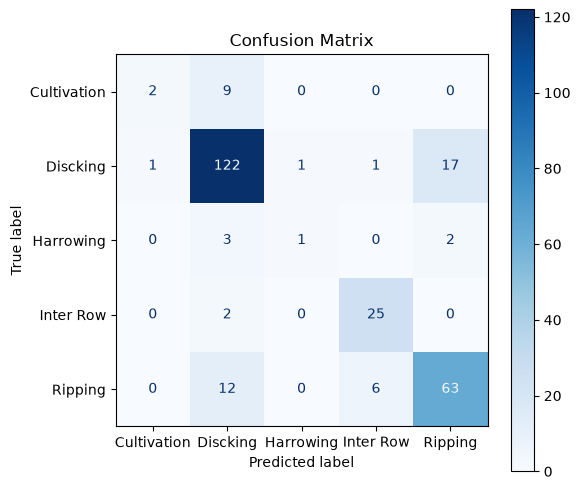


--- Top 5 Important Features ---
1. NDVI__min__mean: 0.3134
2. NDTI__min__mean: 0.2545
3. STI__min__mean: 0.2459
4. extra_noise: 0.1861


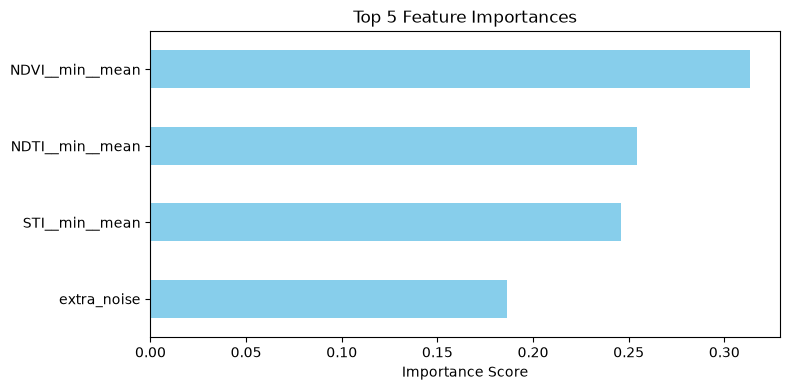

Accuracy --  0.797752808988764  F1 Score --  0.7850695583391064


In [79]:
# ==============================================================================
# 3.-- NOMINAL CLASSES 
# ==============================================================================
target_to_use = 'Nominal' # Options -- baseline (Classifica column), baseline_other(other class included), 
                                            # alex , alex_binary ,
                                            # Nominal, 
                                            # [NOT IMPELEMETD => ]
                                            ## Alex sustainability Score 
                                            #### This is currently approximate. In depth feature extraction with given depth, turnover etc need to be considered. 

mldf = classify_tillage(mldf,target_to_use)
trainables = [col for col in merged_df.columns if '__'  in col]
mldf = mldf[mldf.Target != 'Plowing']
print('Plowing fields have a lot of nans for some reason.')

print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Multiclass classification')
acc , f1 = RFC(mldf ,trainables) 
print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- One vs All
Class Cultivation


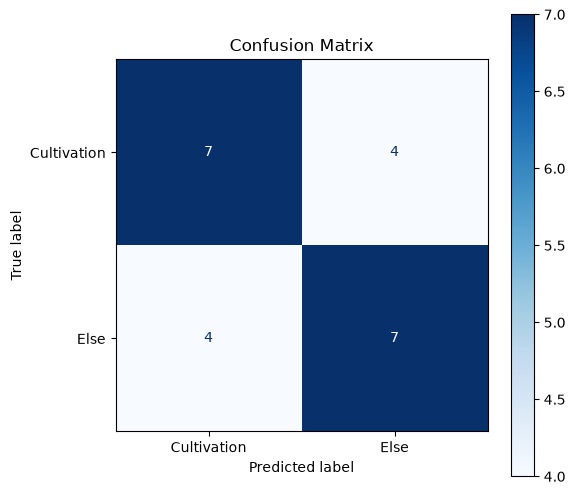


--- Top 5 Important Features ---
1. NDVI__min__mean: 0.3181
2. NDTI__min__mean: 0.2663
3. STI__min__mean: 0.2478
4. extra_noise: 0.1678


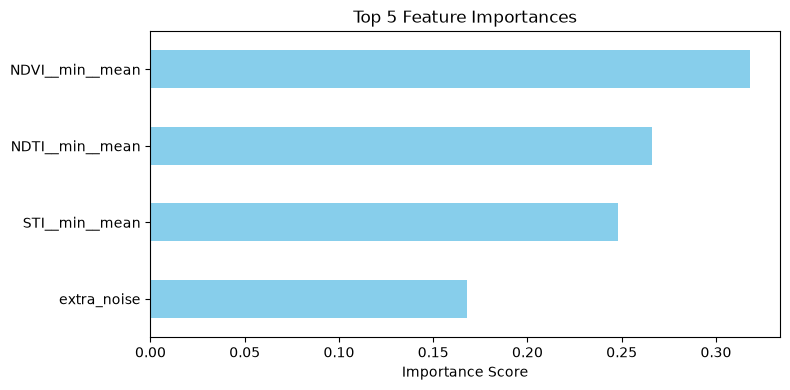

Accuracy --  0.6363636363636364  F1 Score --  0.6363636363636364
Class Discking


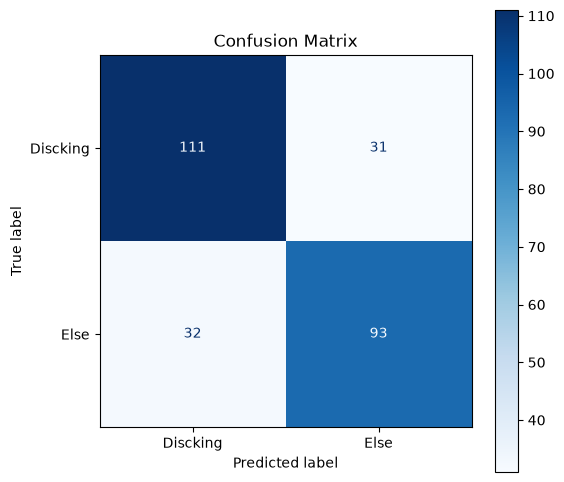


--- Top 5 Important Features ---
1. NDVI__min__mean: 0.3102
2. NDTI__min__mean: 0.2503
3. STI__min__mean: 0.2387
4. extra_noise: 0.2007


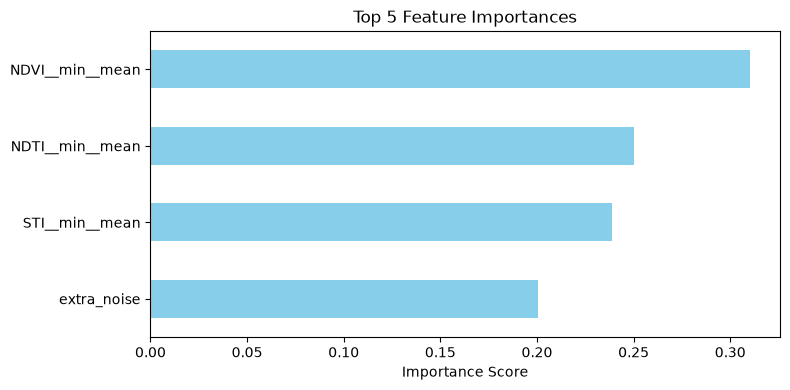

Accuracy --  0.7640449438202247  F1 Score --  0.7639850947254422
Class Harrowing


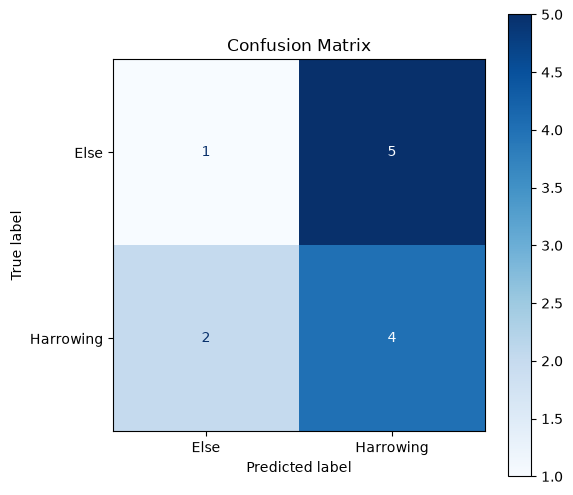


--- Top 5 Important Features ---
1. NDVI__min__mean: 0.4229
2. NDTI__min__mean: 0.2256
3. STI__min__mean: 0.1995
4. extra_noise: 0.1520


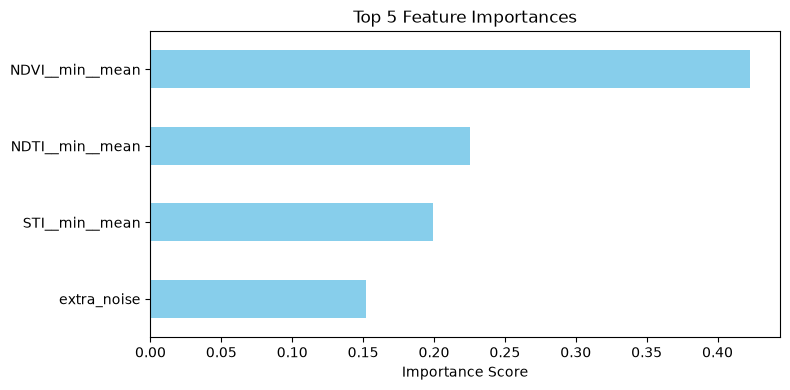

Accuracy --  0.4166666666666667  F1 Score --  0.37777777777777777
Class Inter Row


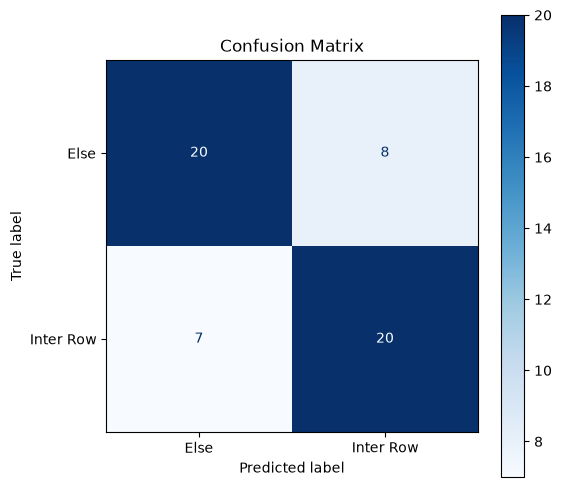


--- Top 5 Important Features ---
1. NDVI__min__mean: 0.4292
2. NDTI__min__mean: 0.2605
3. STI__min__mean: 0.2169
4. extra_noise: 0.0935


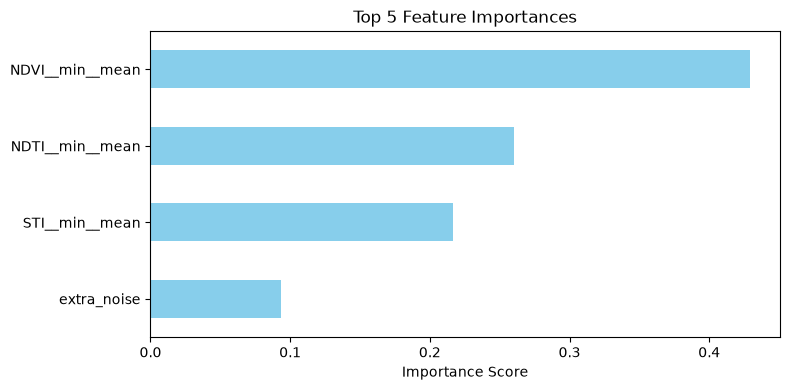

Accuracy --  0.7272727272727273  F1 Score --  0.7272727272727273
Class Ripping


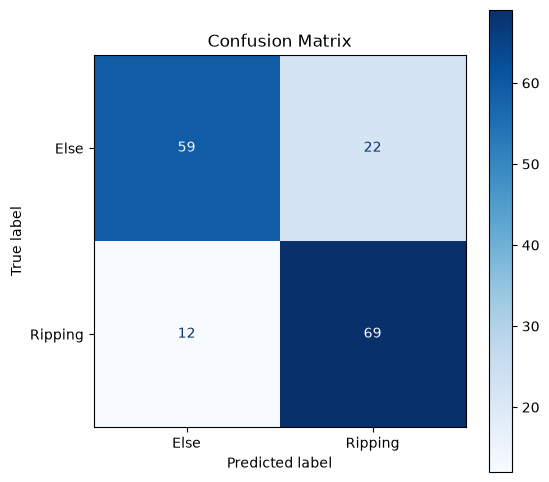


--- Top 5 Important Features ---
1. NDVI__min__mean: 0.2844
2. STI__min__mean: 0.2618
3. NDTI__min__mean: 0.2608
4. extra_noise: 0.1929


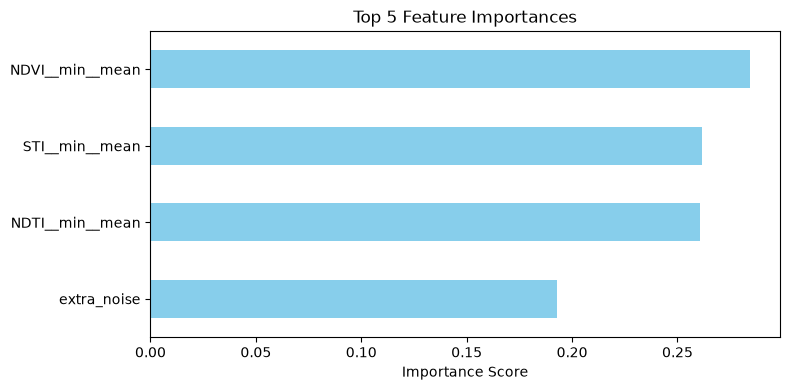

Accuracy --  0.7901234567901234  F1 Score --  0.7893206854345165
Strategy -- Best pair


'This strategy asks the question - Given the data, which two classes are best seperable?'

In [80]:
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- One vs All') 
ova_df = mldf.copy()
for tillage_class in np.unique(mldf.Target):
    print('Class', tillage_class)
    if(len(mldf[mldf.Target == tillage_class]) <6):
        print('Skipping since low count')
        continue
    ova_df = balance_one_vs_all_df(mldf, target_col="Target", target_class=tillage_class)
    acc , f1 = RFC(ova_df ,trainables) 
    print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )

print('Strategy -- Best pair')
'''This strategy asks the question - Given the data, which two classes are best seperable?'''

In [ ]:
acc

0.26666666666666666

In [ ]:
# ==============================================================================
# 3. ML & VISUALIZATION -- NOMINAL CLASSES 
# ==============================================================================
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Ordinal Regression -- ')

In [ ]:
1/0

In [ ]:
# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION
# ==============================================================================

if(target_to_use == 'baseline'):
    # Encode target: Conventional = 0, Conservation = 1
    analysis_df["binary_target"] = (analysis_df["Target"].str.lower() == "conservation").astype(int)
elif(target_to_use == 'alex_binary'): 
    #minval = min(analysis_df.Target)
    val = analysis_df.Target.mean()
    analysis_df["binary_target"] =  (analysis_df['Target'] > val).astype(int)
else: 
    raise NotImplementedError 
y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1_unidirectional, best_acc_unidirectional, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    
    if(target_to_use in ['baseline', 'alex_binary']):
        y_pred = (scores >= t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
    elif(target_to_use == 'alex'): 

        f1 = f1_score(y_true, y_pred, zero_division=0, average = 'micro') 
    else:
        NotImplementedError
    acc = accuracy_score(y_true, y_pred) 
    f1 = f1 if f1>0.5 else 1-f1 
    acc = acc if acc>0.5 else 1-acc
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc_unidirectional or (f1 > best_f1_unidirectional and acc == best_acc_unidirectional):
        best_f1_unidirectional, best_acc_unidirectional, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score (Unidirectional):     {best_f1_unidirectional:.4f}")
print(f"Overall Accuracy (Unidirectional):       {best_acc_unidirectional:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

label0 , label1 = np.unique(analysis_df['Target'].astype(str))
ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label=label0)
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label=label1)
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



NotImplementedError: 

In [ ]:
1/0

In [ ]:
# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION -- COPY
# ==============================================================================

if(target_to_use == 'baseline'):
    # Encode target: Conventional = 0, Conservation = 1
    analysis_df["binary_target"] = (analysis_df["Target"].str.lower() == "conservation").astype(int)
elif(target_to_use == 'alex'): 
    minval = min(analysis_df.Target)
    analysis_df["binary_target"] =  analysis_df['binary_target'] - minval  
else: 
    raise NotImplementedError 
y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1, best_acc, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    y_pred = (scores >= t).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc or (f1 > best_f1 and acc == best_acc):
        best_f1, best_acc, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score:     {best_f1:.4f}")
print(f"Overall Accuracy:       {best_acc:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label="Conventional")
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label="Conservation")
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()